# 06 - Text + Image Fusion

Goal: combine the text and image models and check if this beats the best text model.

We compare:
- **Simple fusion:** a weighted average of the SVM and image probabilities, with one fixed weight.
- **Random Forest (stacking):** a second model that learns how to combine the probabilities of CamemBERT, the SVM and the image model (81 numbers per product).

## 1. Text probabilities

We use the optimised text model from notebook 04 (all features, binary TF-IDF, LinearSVC with C = 1). A LinearSVC gives scores, not probabilities. Calibration learns on the training set (3-fold CV) how to turn these scores into probabilities.

In [1]:
import matplotlib.pyplot as plt
import time

import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC

from src.categories import CATEGORY_NAMES
from src.metrics import compute_per_class_metrics

data = pd.read_csv("../data/processed/text_train_processed.csv")
train = data[data["split"] == "train"]
validation = data[data["split"] == "validation"]

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, binary=True)
X_train = vectorizer.fit_transform(train["text_combined"])
X_validation = vectorizer.transform(validation["text_combined"])

# Optimised LinearSVC from notebook 04, wrapped to output probabilities
text_model = CalibratedClassifierCV(LinearSVC(C=1, random_state=42), cv=3)
text_model.fit(X_train, train["prdtypecode"])
classes = text_model.classes_

text_probs = pd.DataFrame(text_model.predict_proba(X_validation), columns=classes)
text_probs.insert(0, "row_id", validation["row_id"].to_numpy())
text_probs.to_csv("../data/processed/text_validation_probabilities.csv", index=False)

print(f"Text probabilities saved: {text_probs.shape}")
print(f"Each row sums to 1: {np.allclose(text_probs[classes].sum(axis=1), 1)}")

Text probabilities saved: (16984, 28)
Each row sums to 1: True


## 2. Match text and image on the same products

In [2]:
image = pd.read_csv("../data/processed/image_validation_predictions.csv")
image_probs = image[["row_id"] + [f"prob_{c}" for c in classes]]
image_probs.columns = ["row_id"] + list(classes)

both = (
    validation[["row_id", "prdtypecode"]]
    .merge(text_probs, on="row_id")
    .merge(image_probs, on="row_id", suffixes=("_text", "_image"))
)
y_true = both["prdtypecode"].to_numpy()
P_text = both[[f"{c}_text" for c in classes]].to_numpy()
P_image = both[[f"{c}_image" for c in classes]].to_numpy()

print(f"Products scored by both: {len(both)}")

Products scored by both: 16984


## 3. Combine the models

Text and image probabilities exist for the 16984 validation products, which none of the models were trained on. We score every method with 5-fold cross-validation on these products: the combiner learns on 4/5 of them and predicts the remaining 1/5. Every product is predicted by a combiner that never saw it.

For simple fusion, the text weight (0 to 1, in steps of 0.1) is chosen on the 4/5 part only, in the same way.

Text weight chosen in each fold: [0.7, 0.7, 0.7, 0.7, 0.7]


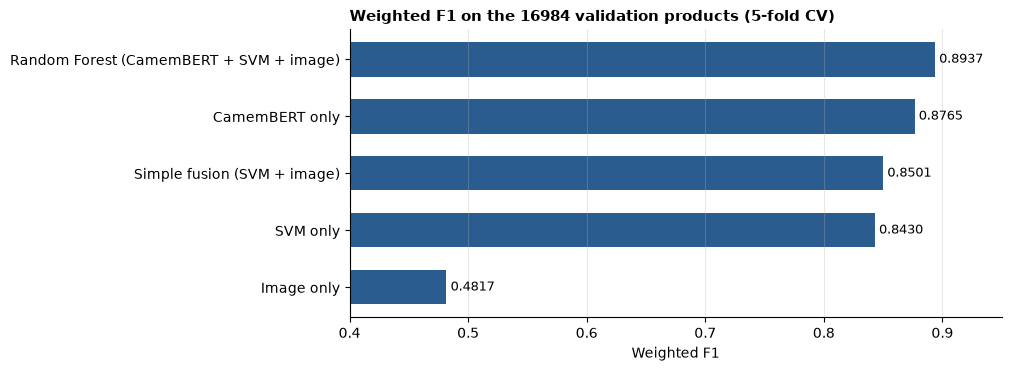

Model,Weighted F1,Macro F1
Random Forest (CamemBERT + SVM + image),0.8937,0.8801
CamemBERT only,0.8765,0.8594
Simple fusion (SVM + image),0.8501,0.8401
SVM only,0.8430,0.8326
Image only,0.4817,0.4230


In [3]:
camembert = pd.read_csv("../data/processed/camembert_validation_probabilities.csv")
P_camembert = both[["row_id"]].merge(camembert, on="row_id")[[str(c) for c in classes]].to_numpy()

X_all = np.hstack([P_camembert, P_text, P_image])
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
weights = np.round(np.arange(0, 1.01, 0.1), 1)

predictions = {
    "Image only": classes[P_image.argmax(axis=1)],
    "SVM only": classes[P_text.argmax(axis=1)],
    "CamemBERT only": classes[P_camembert.argmax(axis=1)],
    "Simple fusion (SVM + image)": np.zeros_like(y_true),
    "Random Forest (CamemBERT + SVM + image)": np.zeros_like(y_true),
}
chosen_weights = []
for train_idx, test_idx in folds.split(X_all, y_true):
    fold_scores = [
        f1_score(y_true[train_idx], classes[(w * P_text[train_idx] + (1 - w) * P_image[train_idx]).argmax(axis=1)], average="weighted")
        for w in weights
    ]
    best_w = weights[int(np.argmax(fold_scores))]
    chosen_weights.append(float(best_w))
    predictions["Simple fusion (SVM + image)"][test_idx] = classes[(best_w * P_text[test_idx] + (1 - best_w) * P_image[test_idx]).argmax(axis=1)]

    forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=42)
    predictions["Random Forest (CamemBERT + SVM + image)"][test_idx] = forest.fit(X_all[train_idx], y_true[train_idx]).predict(X_all[test_idx])

print(f"Text weight chosen in each fold: {chosen_weights}")
results = pd.DataFrame({
    "Model": list(predictions),
    "Weighted F1": [f1_score(y_true, p, average="weighted") for p in predictions.values()],
    "Macro F1": [f1_score(y_true, p, average="macro") for p in predictions.values()],
})

fig, ax = plt.subplots(figsize=(10, 3.6), constrained_layout=True)
ordered = results.sort_values("Weighted F1")
bars = ax.barh(ordered["Model"], ordered["Weighted F1"], color="#2b5c8f", height=0.6)
ax.bar_label(bars, labels=[f"{v:.4f}" for v in ordered["Weighted F1"]], padding=3, fontsize=9)
ax.set_xlim(0.4, 0.95)
ax.set_title("Weighted F1 on the 16984 validation products (5-fold CV)", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Weighted F1")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
plt.show()

results.sort_values("Weighted F1", ascending=False).style.hide(axis="index").format(precision=4)

### Analysis

- The best model is the Random Forest on CamemBERT, SVM and image: 0.8937 weighted F1 and 0.8801 macro F1.
- That is +1.7 points over CamemBERT alone (0.8765) and +5.1 points over the SVM alone (0.8430).
- Simple fusion with one fixed weight (70% SVM, 30% image) reaches 0.8501: images help, but a fixed weight cannot use them well.
- We also tried Gradient Boosting instead of Random Forest. It scored slightly lower (0.8595 against 0.8630 on SVM + image) and was much slower, so we kept the Random Forest.

## 4. Per category: best fusion vs CamemBERT

In [4]:
best = "Random Forest (CamemBERT + SVM + image)"
camembert_scores = compute_per_class_metrics(y_true, predictions["CamemBERT only"], classes)
best_scores = compute_per_class_metrics(y_true, predictions[best], classes)

per_class = pd.DataFrame({
    "Code": classes,
    "Category": [CATEGORY_NAMES[c] for c in classes],
    "CamemBERT F1": camembert_scores["f1"],
    "Best fusion F1": best_scores["f1"],
})
per_class["Gain"] = per_class["Best fusion F1"] - per_class["CamemBERT F1"]
per_class.sort_values("Gain", ascending=False).style.hide(axis="index").format(precision=3)

Code,Category,CamemBERT F1,Best fusion F1,Gain
1180,Wargames,0.614,0.691,0.078
2705,New Books,0.818,0.892,0.075
10,Used Books,0.689,0.754,0.065
1302,Outdoor Toys,0.810,0.854,0.045
40,Games,0.795,0.831,0.036
2585,Garden Tools,0.823,0.849,0.026
2220,Pets,0.890,0.915,0.026
60,Consoles,0.876,0.901,0.024
1320,Baby,0.856,0.877,0.021
2582,Garden Furniture,0.794,0.815,0.020


### Analysis

- The best fusion is better than CamemBERT on 26 of the 27 categories. Only Baby Socks drops slightly (-0.3 points).
- The largest gains are on Wargames (+7.8 points), New Books (+7.5) and Used Books (+6.5).
- Wargames was CamemBERT's weakest point. The SVM catches its rare exact words (*warhammer*, *heroclix*), so combining both fixes it.
- Books gain from both the SVM and the image.

## Conclusion

- Combining models helps, and a learned combination (Random Forest) works better than a fixed weight.
- Best model: Random Forest on the CamemBERT, SVM and image probabilities, with 0.8937 weighted F1 on the validation products (5-fold CV).
- Each part adds something: CamemBERT reads context, the SVM catches rare specific words, and the image helps on books.